In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
df = pd.read_excel(r"C:\Users\eedau\Batch 12 pm to 2 pm\PJMW_MW_Hourly (2).xlsx")
df

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930
...,...,...
143201,2018-01-01 20:00:00,8401
143202,2018-01-01 21:00:00,8373
143203,2018-01-01 22:00:00,8238
143204,2018-01-01 23:00:00,7958


In [53]:
print(df.head())

             Datetime  PJMW_MW
0 2002-12-31 01:00:00     5077
1 2002-12-31 02:00:00     4939
2 2002-12-31 03:00:00     4885
3 2002-12-31 04:00:00     4857
4 2002-12-31 05:00:00     4930


In [55]:
print(df.shape)

(143206, 2)


In [56]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB
None


In [57]:
print(df.describe())

                            Datetime        PJMW_MW
count                         143206  143206.000000
mean   2010-06-02 03:39:50.656816128    5602.375089
min              2002-04-01 01:00:00     487.000000
25%              2006-05-02 03:15:00    4907.000000
50%              2010-06-02 04:30:00    5530.000000
75%              2014-07-03 06:45:00    6252.000000
max              2018-08-03 00:00:00    9594.000000
std                              NaN     979.142872


In [58]:
print(df.isnull().sum())

Datetime    0
PJMW_MW     0
dtype: int64


In [59]:
from statsmodels.graphics.tsaplots import plot_acf

In [60]:
df = df.sort_values("Datetime")
df = df.drop_duplicates("Datetime")
df = df.set_index("Datetime")
df = df.asfreq("h")
print("Missing hours:", df["PJMW_MW"].isna().sum())

Missing hours: 30


In [61]:
df.loc[df["PJMW_MW"] < 1500, "PJMW_MW"] = np.nan
df = df.interpolate(method="time")
print("Missing after fixing:", df["PJMW_MW"].isna().sum())

Missing after fixing: 0


In [62]:
print(" FEATURE ENGINEERING")
df["hour"] = df.index.hour
df["day_of_week"] = df.index.dayofweek
df["month"] = df.index.month
df["year"] = df.index.year
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

 FEATURE ENGINEERING


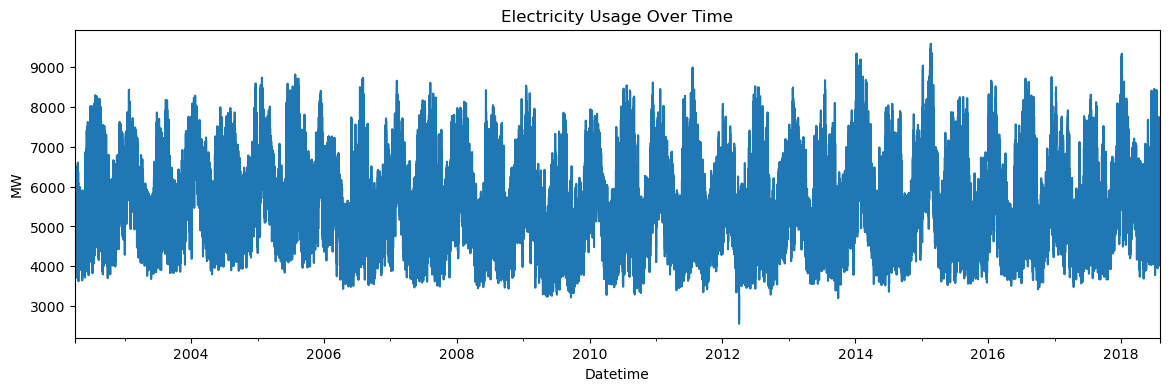

In [63]:
df["PJMW_MW"].plot(figsize=(14, 4))
plt.title("Electricity Usage Over Time")
plt.ylabel("MW")
plt.show()

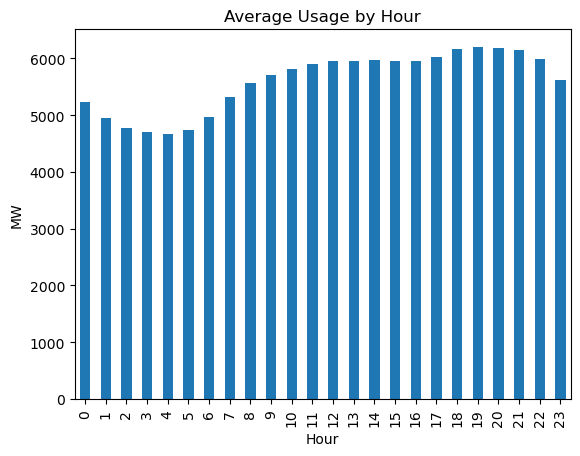

In [64]:
df.groupby("hour")["PJMW_MW"].mean().plot(kind="bar")
plt.title("Average Usage by Hour")
plt.xlabel("Hour")
plt.ylabel("MW")
plt.show()

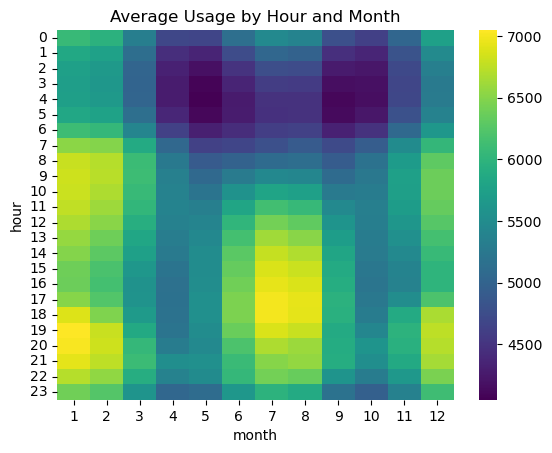

In [65]:
data = df.pivot_table(
    index="hour",
    columns="month",
    values="PJMW_MW"
)

sns.heatmap(data, cmap="viridis")
plt.title("Average Usage by Hour and Month")
plt.show()

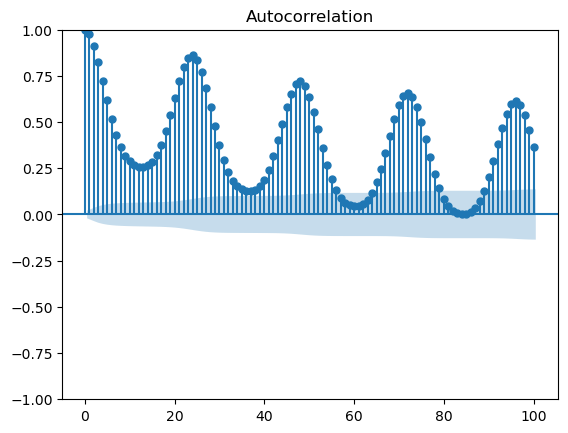

In [66]:
plot_acf(df["PJMW_MW"].loc["2017"], lags=100)
plt.show()

In [67]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
df

,PJMW_MW,hour,day_of_week,month,year,is_weekend,hour_sin,hour_cos,month_sin,month_cos
Datetime,,,,,,,,,,
2002-04-01 01:00:00,4374.0,1,0,4,2002,0,0.258819,0.965926,0.866025,-0.5
2002-04-01 02:00:00,4306.0,2,0,4,2002,0,0.500000,0.866025,0.866025,-0.5
2002-04-01 03:00:00,4322.0,3,0,4,2002,0,0.707107,0.707107,0.866025,-0.5
2002-04-01 04:00:00,4359.0,4,0,4,2002,0,0.866025,0.500000,0.866025,-0.5
2002-04-01 05:00:00,4436.0,5,0,4,2002,0,0.965926,0.258819,0.866025,-0.5
...,...,...,...,...,...,...,...,...,...,...
2018-08-02 20:00:00,6545.0,20,3,8,2018,0,-0.866025,0.500000,-0.866025,-0.5
2018-08-02 21:00:00,6496.0,21,3,8,2018,0,-0.707107,0.707107,-0.866025,-0.5
2018-08-02 22:00:00,6325.0,22,3,8,2018,0,-0.500000,0.866025,-0.866025,-0.5


In [68]:
df["lag_1"] = df["PJMW_MW"].shift(1)
df["lag_24"] = df["PJMW_MW"].shift(24)
df["lag_168"] = df["PJMW_MW"].shift(168)
df

,PJMW_MW,hour,day_of_week,month,year,is_weekend,hour_sin,hour_cos,month_sin,month_cos,lag_1,lag_24,lag_168
Datetime,,,,,,,,,,,,,
2002-04-01 01:00:00,4374.0,1,0,4,2002,0,0.258819,0.965926,0.866025,-0.5,NaN,NaN,NaN
2002-04-01 02:00:00,4306.0,2,0,4,2002,0,0.500000,0.866025,0.866025,-0.5,4374.0,NaN,NaN
2002-04-01 03:00:00,4322.0,3,0,4,2002,0,0.707107,0.707107,0.866025,-0.5,4306.0,NaN,NaN
2002-04-01 04:00:00,4359.0,4,0,4,2002,0,0.866025,0.500000,0.866025,-0.5,4322.0,NaN,NaN
2002-04-01 05:00:00,4436.0,5,0,4,2002,0,0.965926,0.258819,0.866025,-0.5,4359.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-08-02 20:00:00,6545.0,20,3,8,2018,0,-0.866025,0.500000,-0.866025,-0.5,6693.0,6816.0,7354.0
2018-08-02 21:00:00,6496.0,21,3,8,2018,0,-0.707107,0.707107,-0.866025,-0.5,6545.0,6571.0,7063.0
2018-08-02 22:00:00,6325.0,22,3,8,2018,0,-0.500000,0.866025,-0.866025,-0.5,6496.0,6362.0,6895.0


In [69]:
df = df.copy()

df["rolling_24"] = (
    df["PJMW_MW"]
    .shift(1)
    .rolling(24)
    .mean()
)

df["rolling_168"] = (
    df["PJMW_MW"]
    .shift(1)
    .rolling(168)
    .mean()
)

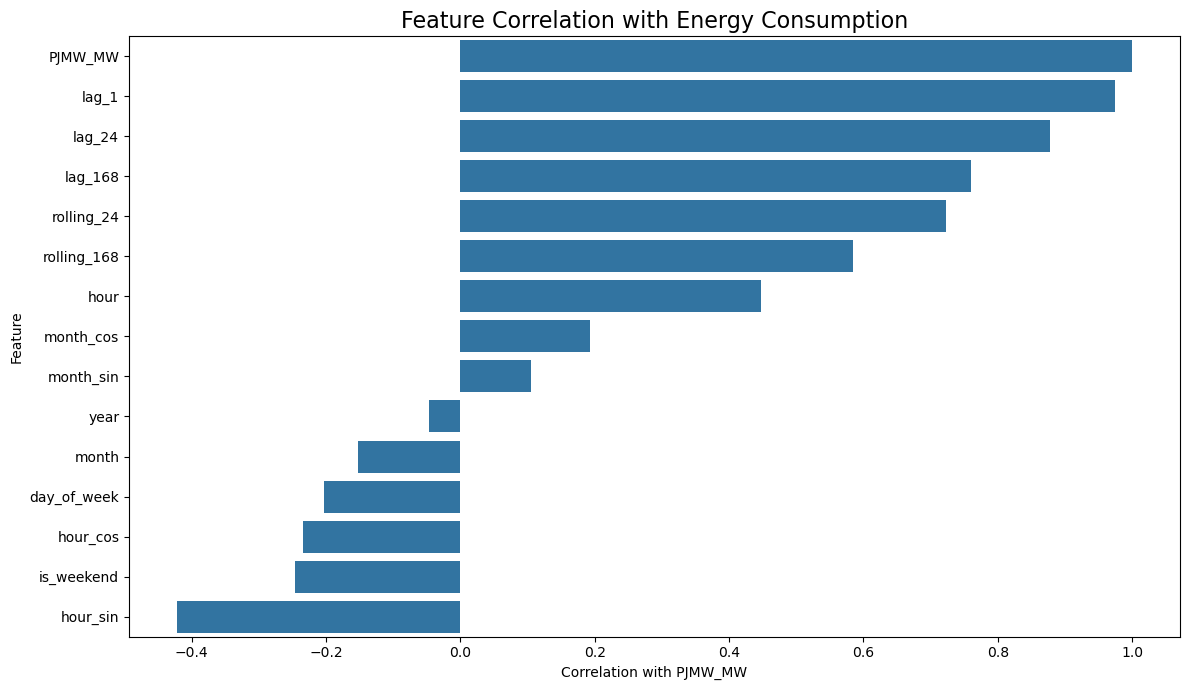

In [70]:
plt.figure(figsize=(12, 7))

correlations = (
    df.corr(numeric_only=True)["PJMW_MW"]
    .sort_values(ascending=False)
)

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.title(
    "Feature Correlation with Energy Consumption",
    fontsize=16
)

plt.xlabel("Correlation with PJMW_MW")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [71]:
df = df.dropna()

In [72]:
print(df.corr()["PJMW_MW"].sort_values(ascending=False))

PJMW_MW        1.000000
lag_1          0.974841
lag_24         0.877320
lag_168        0.759970
rolling_24     0.723301
rolling_168    0.583917
hour           0.447339
month_cos      0.193141
month_sin      0.105318
year          -0.047368
month         -0.152651
day_of_week   -0.203208
hour_cos      -0.233921
is_weekend    -0.245884
hour_sin      -0.422122
Name: PJMW_MW, dtype: float64


In [73]:
df

,PJMW_MW,hour,day_of_week,month,year,is_weekend,hour_sin,hour_cos,month_sin,month_cos,lag_1,lag_24,lag_168,rolling_24,rolling_168
Datetime,,,,,,,,,,,,,,,
2002-04-08 01:00:00,4634.0,1,0,4,2002,0,0.258819,0.965926,0.866025,-0.5,4798.0,5002.0,4374.0,5039.229167,5380.711310
2002-04-08 02:00:00,4532.0,2,0,4,2002,0,0.500000,0.866025,0.866025,-0.5,4634.0,4858.0,4306.0,5023.895833,5382.258929
2002-04-08 03:00:00,4481.0,3,0,4,2002,0,0.707107,0.707107,0.866025,-0.5,4532.0,4864.5,4322.0,5010.312500,5383.604167
2002-04-08 04:00:00,4527.0,4,0,4,2002,0,0.866025,0.500000,0.866025,-0.5,4481.0,4871.0,4359.0,4994.333333,5384.550595
2002-04-08 05:00:00,4640.0,5,0,4,2002,0,0.965926,0.258819,0.866025,-0.5,4527.0,4909.0,4436.0,4980.000000,5385.550595
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-08-02 20:00:00,6545.0,20,3,8,2018,0,-0.866025,0.500000,-0.866025,-0.5,6693.0,6816.0,7354.0,5820.541667,5681.827381
2018-08-02 21:00:00,6496.0,21,3,8,2018,0,-0.707107,0.707107,-0.866025,-0.5,6545.0,6571.0,7063.0,5809.250000,5677.011905
2018-08-02 22:00:00,6325.0,22,3,8,2018,0,-0.500000,0.866025,-0.866025,-0.5,6496.0,6362.0,6895.0,5806.125000,5673.636905


In [74]:
df.columns

Index(['PJMW_MW', 'hour', 'day_of_week', 'month', 'year', 'is_weekend',
       'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'lag_1', 'lag_24',
       'lag_168', 'rolling_24', 'rolling_168'],
      dtype='object')

In [75]:
df.to_csv("PJMW_features.csv")
print("Saved!")

Saved!
